# De Bruijn's identity

*Under Gaussian smoothing, differential entropy grows at exactly half the rate of Fisher information*

**Probability Notes No. 01** · Omid Shams Solari, Ph.D. · 9 November 2026

[PDF (A4)](pdf/pn-01-debruijn.pdf) · [PDF (screen)](pdf/pn-01-debruijn-screen.pdf) · [Article](article.md) · [LaTeX source](main.tex)

> **TL;DR.** Adding independent Gaussian noise to a random variable makes it more spread out, so its differential entropy grows with the noise variance. De Bruijn’s identity, published by Stam (1959), gives the rate exactly: the derivative of the entropy with respect to the noise variance is half the Fisher information of the noisy variable. Fisher information is therefore the speed at which Gaussian smoothing creates entropy.

## Result

> **Theorem 1 (de Bruijn; Stam, 1959).** Under Assumption A1, for every $t>0$ the entropy $h(Y_t)$ and the Fisher information $J(Y_t)$ are finite, $J(Y_t)\le 1/t$, and $t\mapsto h(Y_t)$ is differentiable on $(0,\infty)$ with
>
> $$
> \frac{\mathrm{d}}{\mathrm{d}t}\,h\big(X+\sqrt t\,Z\big)=\frac12\,J\big(X+\sqrt t\,Z\big). \tag{1}
> $$

**Remark 2.** For $X\sim\mathcal{N}(\mu,\sigma^2)$, $Y_t\sim\mathcal{N}(\mu,\sigma^2+t)$, so $h(Y_t)=\tfrac12\log\big(2\pi e(\sigma^2+t)\big)$ and $\rho_t(y)=-(y-\mu)/(\sigma^2+t)$, giving $J(Y_t)=1/(\sigma^2+t)$. Both sides of (1) equal $1/\big(2(\sigma^2+t)\big)$.

## Numerical check

The cells below are `code/check.py`, split at its numbered sections; together they print every number in this table.

All quantities use adaptive quadrature of the closed forms above; $\mathrm{d}h/\mathrm{d}t$ uses a four-point central difference with step $10^{-3}$.

| Case                                                                           |        Exact         |      Numerical       |
|:-------------------------------------------------------------------------------|:--------------------:|:--------------------:|
| $X\sim\mathcal{N}(0,1)$, $t=1$: $\mathrm{d}h/\mathrm{d}t$                      |        $1/4$         |      $0.250000$      |
| $X\sim\mathcal{N}(0,1)$, $t=1$: $J(Y_t)$                                       |        $1/2$         |      $0.500000$      |
| $X=\pm1$, $t=\tfrac12$: $\mathrm{d}h/\mathrm{d}t-\tfrac12J(Y_t)$               |         $0$          | $-1.9\times10^{-11}$ |
| $X=\pm1$, $t=\tfrac12$: $J(Y_t)-\big(\tfrac1t-\tfrac{\mathrm{mmse}}{t^2}\big)$ |         $0$          | $2.2\times10^{-16}$  |
| $X=\pm1$: $h(Y_1)-h(Y_{1/2})$                                                  | in $[0.1438,0.3466]$ |       $0.1833$       |

Rows 1–2 check Remark 2; rows 3–5 check (1), Corollary 9 and Corollary 8 for a discrete input. Rows 3–4 are at rounding level, so their last digits may vary across library versions.

### Setup

In [1]:
"""Probability Notes No. 01: numerical check.

Prints every number in the PDF's check table.
Requires Python >= 3.8, NumPy >= 1.20 and
SciPy >= 1.6.
Tested with Python 3.13, NumPy 2.5, SciPy 1.18.
Run: python3 check.py
"""
import numpy as np
from scipy.integrate import quad

def logphi(z, t):
    return -z * z / (2 * t) - 0.5 * np.log(2 * np.pi * t)

# Y_t = X + sqrt(t) Z for two inputs X.
# Each returns (log p_t(y), score p_t'(y)/p_t(y)).
def gauss(y, t):   # X ~ N(0, 1)
    v = 1 + t
    return logphi(y, v), -y / v

def lcosh(u):      # log cosh, overflow-safe
    u = abs(u)
    return u + np.log1p(np.exp(-2 * u)) - np.log(2)

def rade(y, t):    # X = +1 or -1, prob 1/2 each
    lp = logphi(y, t) + lcosh(y / t) - 1 / (2 * t)
    return lp, (np.tanh(y / t) - y) / t

def E(f, model, t):
    """E[f(y)] under Y_t, adaptive quadrature."""
    L = 2 + 14 * np.sqrt(1 + t)
    def g(y):
        return np.exp(model(y, t)[0]) * f(y)
    return quad(g, -L, L, limit=400, points=[0],
                epsabs=1e-14, epsrel=1e-13)[0]

def h(model, t):        # differential entropy
    return E(lambda y: -model(y, t)[0], model, t)

def J(model, t):        # Fisher information
    return E(lambda y: model(y, t)[1] ** 2, model, t)

def dh(model, t, d=1e-3):   # 4-point difference
    f = [h(model, t + k * d) for k in (-2, -1, 1, 2)]
    return (f[0] - 8 * f[1] + 8 * f[2] - f[3]) / (12 * d)

### 1-2. Gaussian X, t = 1: dh/dt = J/2 = 1/4.

In [2]:
# 1-2. Gaussian X, t = 1: dh/dt = J/2 = 1/4.
print(f"Gauss dh/dt:   {dh(gauss, 1.0):.6f}")
print(f"Gauss J:       {J(gauss, 1.0):.6f}")

Gauss dh/dt:   0.250000
Gauss J:       0.500000


### 3. Rademacher X, t = 1/2: de Bruijn residual.

In [3]:
# 3. Rademacher X, t = 1/2: de Bruijn residual.
t = 0.5
a, b = dh(rade, t), J(rade, t) / 2
print(f"Rade dh/dt:    {a:.6f}")
print(f"Rade J/2:      {b:.6f}")
print(f"Difference:    {a - b:.1e}")

Rade dh/dt:    0.537964
Rade J/2:      0.537964
Difference:    -1.9e-11


### 4. Fisher information versus MMSE: J = 1/t - mmse/t^2, mmse = 1 - E tanh^2(Y/t).

In [4]:
# 4. Fisher information versus MMSE:
#    J = 1/t - mmse/t^2, mmse = 1 - E tanh^2(Y/t).
th2 = E(lambda y: np.tanh(y / t) ** 2, rade, t)
mmse = 1 - th2
print(f"Rade mmse:     {mmse:.6f}")
a, b = J(rade, t), 1 / t - mmse / t ** 2
print(f"Rade J:        {a:.6f}")
print(f"1/t-mmse/t^2:  {b:.6f}")
print(f"Difference:    {a - b:.1e}")

Rade mmse:     0.231018
Rade J:        1.075927
1/t-mmse/t^2:  1.075927
Difference:    2.2e-16


### 5. Entropy sandwich on [1/2, 1], Var X = 1.

In [5]:
# 5. Entropy sandwich on [1/2, 1], Var X = 1.
inc = h(rade, 1.0) - h(rade, 0.5)
lo, hi = 0.5 * np.log(2 / 1.5), 0.5 * np.log(2)
print(f"Increment:     {inc:.4f}")
print(f"Bounds:        [{lo:.4f}, {hi:.4f}]")

Increment:     0.1833
Bounds:        [0.1438, 0.3466]


### 6. Figure data: t J(Y_t) for Rademacher X and the Gaussian lower bound t/(1+t).

In [6]:
# 6. Figure data: t J(Y_t) for Rademacher X
#    and the Gaussian lower bound t/(1+t).
for e in np.linspace(-1.5, 1.5, 25):
    s = 10 ** e
    print(f"fig {e:+.2f} {s * J(rade, s):.4f}"
          f" {s / (1 + s):.4f}")

fig -1.50 1.0000 0.0307
fig -1.38 1.0000 0.0405
fig -1.25 0.9993 0.0532
fig -1.12 0.9946 0.0698
fig -1.00 0.9759 0.0909
fig -0.88 0.9291 0.1177
fig -0.75 0.8483 0.1510
fig -0.62 0.7451 0.1917
fig -0.50 0.6435 0.2403
fig -0.38 0.5664 0.2966
fig -0.25 0.5263 0.3599
fig -0.12 0.5235 0.4285
fig +0.00 0.5504 0.5000
fig +0.12 0.5965 0.5715
fig +0.25 0.6517 0.6401
fig +0.38 0.7085 0.7034
fig +0.50 0.7619 0.7597
fig +0.62 0.8092 0.8083
fig +0.75 0.8493 0.8490
fig +0.88 0.8825 0.8823
fig +1.00 0.9091 0.9091
fig +1.12 0.9303 0.9302
fig +1.25 0.9468 0.9468
fig +1.38 0.9595 0.9595
fig +1.50 0.9693 0.9693


## Figures

`code/figures.py`: matplotlib versions of the PDF's figures.

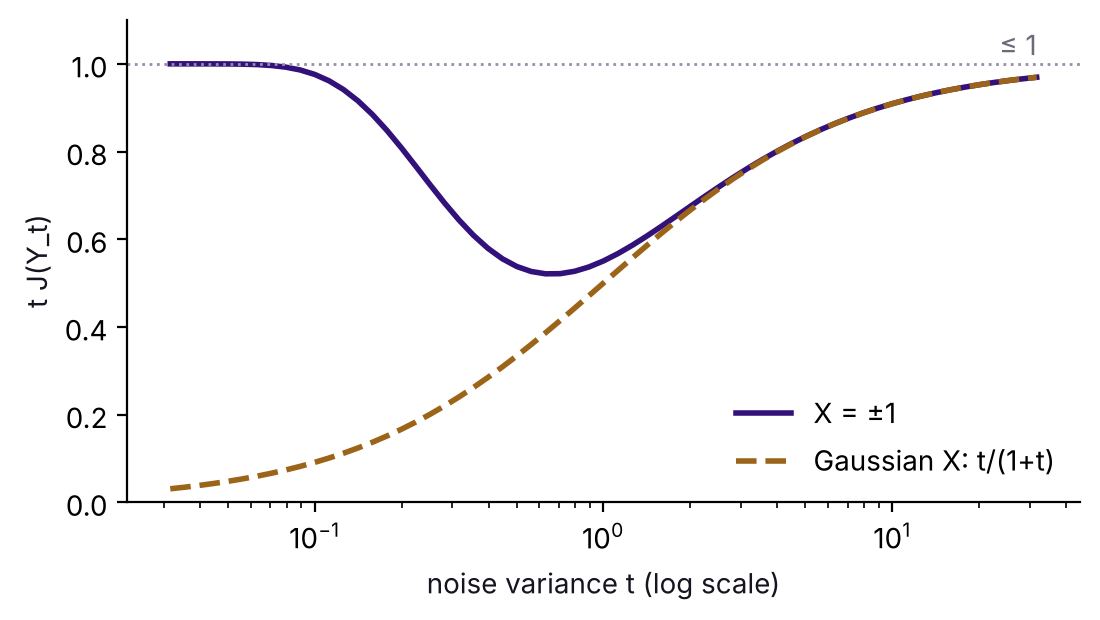

In [7]:
"""Probability Notes No. 01: figures (matplotlib).

Runs in the notebook after check.py, in the same namespace
(uses J and rade from check.py).
Figure 1: t J(Y_t) for X = +-1, between the bounds
t/(1+t) (Gaussian input) and 1.
"""
import matplotlib.pyplot as plt
import numpy as np

INK, MUTED = "#17131F", "#6F6879"
PRI, WARN = "#32127A", "#9B6418"

ts = np.logspace(-1.5, 1.5, 61)
tj = [s * J(rade, s) for s in ts]

fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.semilogx(ts, tj, color=PRI, lw=2, label="X = ±1")
ax.semilogx(ts, ts / (1 + ts), color=WARN, lw=2,
            ls="--", label="Gaussian X: t/(1+t)")
ax.axhline(1, color="#978EA7", ls=":", lw=1)
ax.text(ts[-1], 1.02, "≤ 1", ha="right", color=MUTED)
ax.set_xlabel("noise variance t (log scale)", color=INK)
ax.set_ylabel("t J(Y_t)", color=INK)
ax.set_ylim(0, 1.1)
ax.legend(frameon=False, loc="lower right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()